In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency

In [52]:
df = pd.read_csv("data.csv")

In [53]:
df.head()

,Console,Title,YearReleased,Genre,NASales,EUSales,JapanSales,OtherSales,GlobalSales,Sequel,...,MedievalFantasy,Puzzle,RealTime,SciFi,Shooter,FirstPerson,Isometric,SideScrolling,TopDown,ThirdPerson
0,Sony PSP,007: From Russia with Love,2006,"Action, Racing / Driving",0.07,0.01,0.00,0.01,0.08,1,...,0,0,0,0,0,0,0,0,0,0
1,Sony PSP,300: March to Glory,2007,Action,0.27,0.08,0.00,0.06,0.41,0,...,1,0,0,0,0,0,0,0,0,1
2,PlayStation 3,3D Dot Game Heroes,2010,"Action, Adventure, Strategy",0.36,0.12,0.03,0.07,0.58,0,...,1,1,0,0,0,0,0,0,0,1
3,X360,50 Cent: Blood on the Sand,2009,Action,0.12,0.07,0.00,0.02,0.21,1,...,0,0,0,0,1,0,0,0,0,1
4,PlayStation 3,50 Cent: Blood on the Sand,2009,Action,0.10,0.06,0.01,0.03,0.20,1,...,0,0,0,0,1,0,0,0,0,1


In [54]:
df.shape # 1754 games

(1754, 31)

In [55]:
bool_cols = [
    "Online",
    "Licensed",
    "Handheld",
    "Multiplatform",
    "Anime",
    "Arcade",
    "Fighting",
    "MedievalFantasy",
    "Puzzle",
    "RealTime",
    "SciFi",
    "Shooter",
    "FirstPerson",
    "Isometric",
    "SideScrolling",
    "TopDown",
    "ThirdPerson",
]
df[bool_cols] = df[bool_cols].astype(bool)

In [56]:
numerical_df = df.select_dtypes(include="number").drop(
    columns=[
        "Sequel",
    ]
)
numerical_df.columns

Index(['YearReleased', 'NASales', 'EUSales', 'JapanSales', 'OtherSales',
       'GlobalSales', 'Usedprice', 'ReviewScore', 'MaxPlayers'],
      dtype='object')

In [57]:
numerical_df.describe().round(3)

,YearReleased,NASales,EUSales,JapanSales,OtherSales,GlobalSales,Usedprice,ReviewScore,MaxPlayers
count,1754.000,1754.000,1754.000,1754.000,1754.000,1754.000,1754.000,1754.000,1754.000
mean,2007.361,0.506,0.289,0.094,0.107,0.996,19.443,68.375,1.662
std,1.362,1.138,0.854,0.448,0.252,2.513,7.512,13.897,1.237
min,2004.000,0.010,0.000,0.000,0.000,0.010,4.950,12.000,1.000
25%,2006.000,0.100,0.000,0.000,0.010,0.140,14.950,60.000,1.000
50%,2007.000,0.200,0.030,0.000,0.030,0.340,17.950,70.000,1.000
75%,2008.000,0.460,0.270,0.020,0.100,0.900,19.950,79.000,2.000
max,2010.000,15.850,12.880,6.500,3.310,35.830,49.950,98.000,8.000


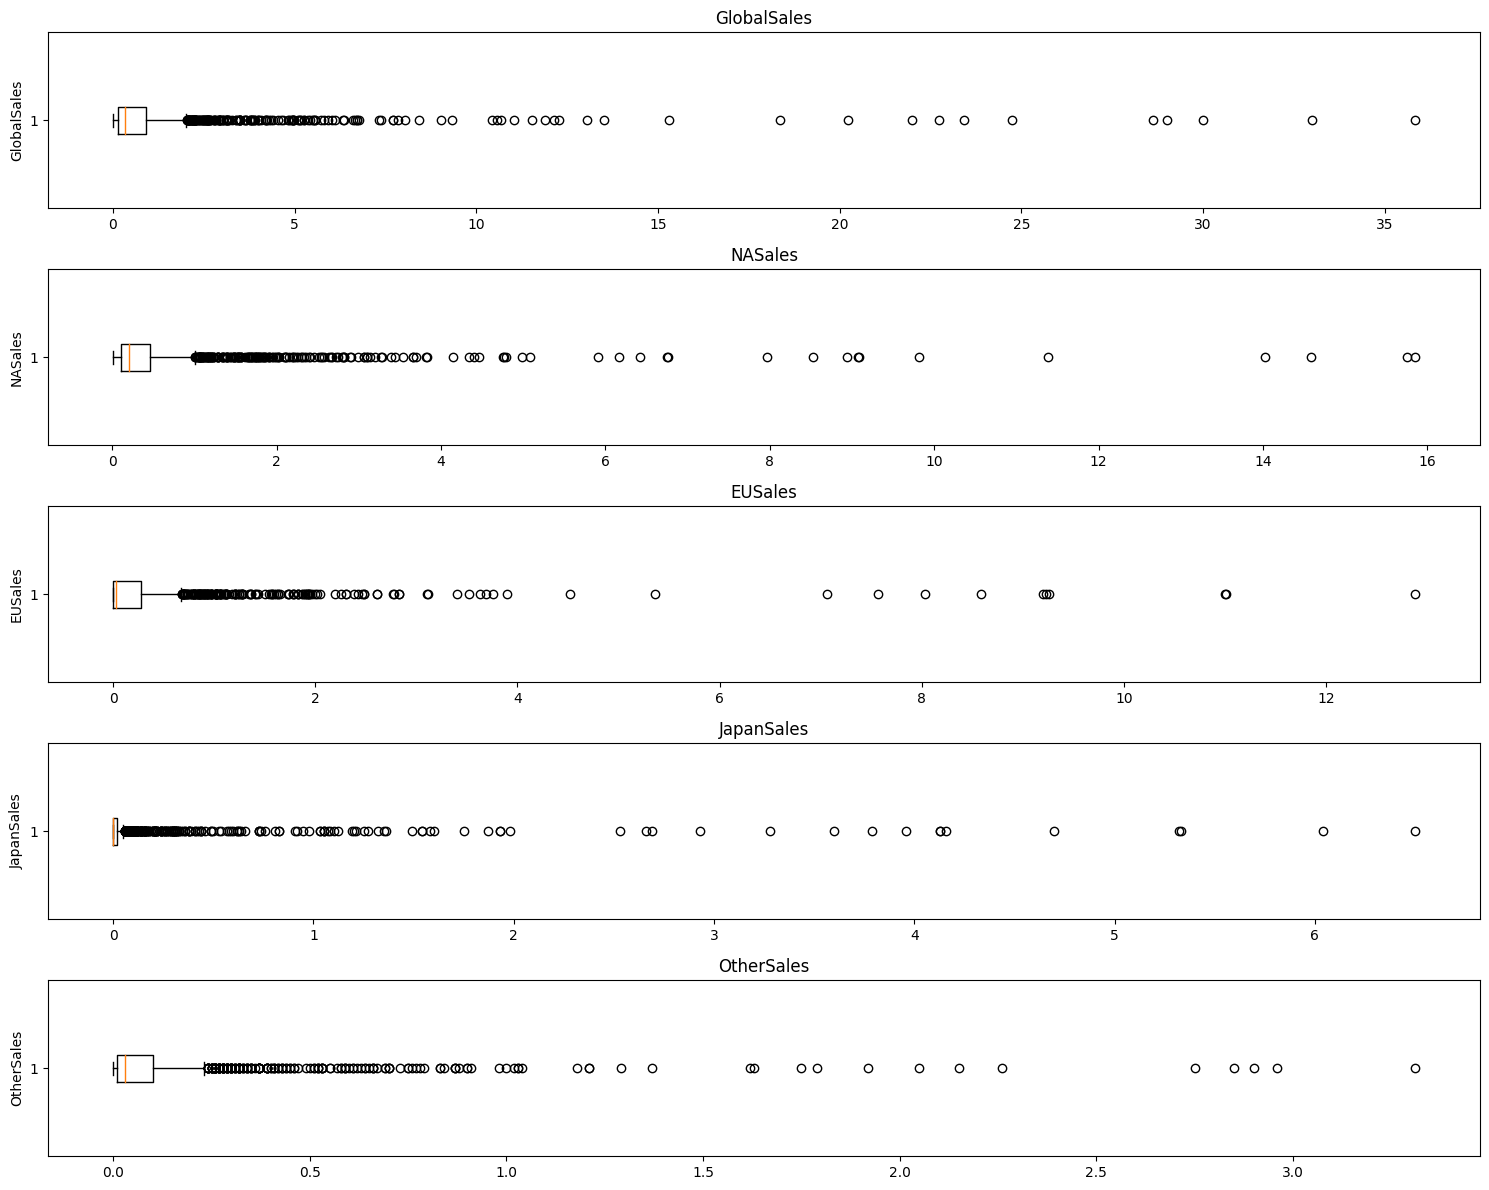

In [58]:
sales_cols = [
    "GlobalSales",
    "NASales",
    "EUSales",
    "JapanSales",
    "OtherSales",
]

fig, axes = plt.subplots(nrows=len(sales_cols), ncols=1, figsize=(15, 12))

axes = axes.flatten()

for i, col in enumerate(sales_cols):
    axes[i].boxplot(numerical_df[col].dropna(), vert=False)
    axes[i].set_title(col)
    axes[i].set_ylabel(col)

for j in range(len(sales_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

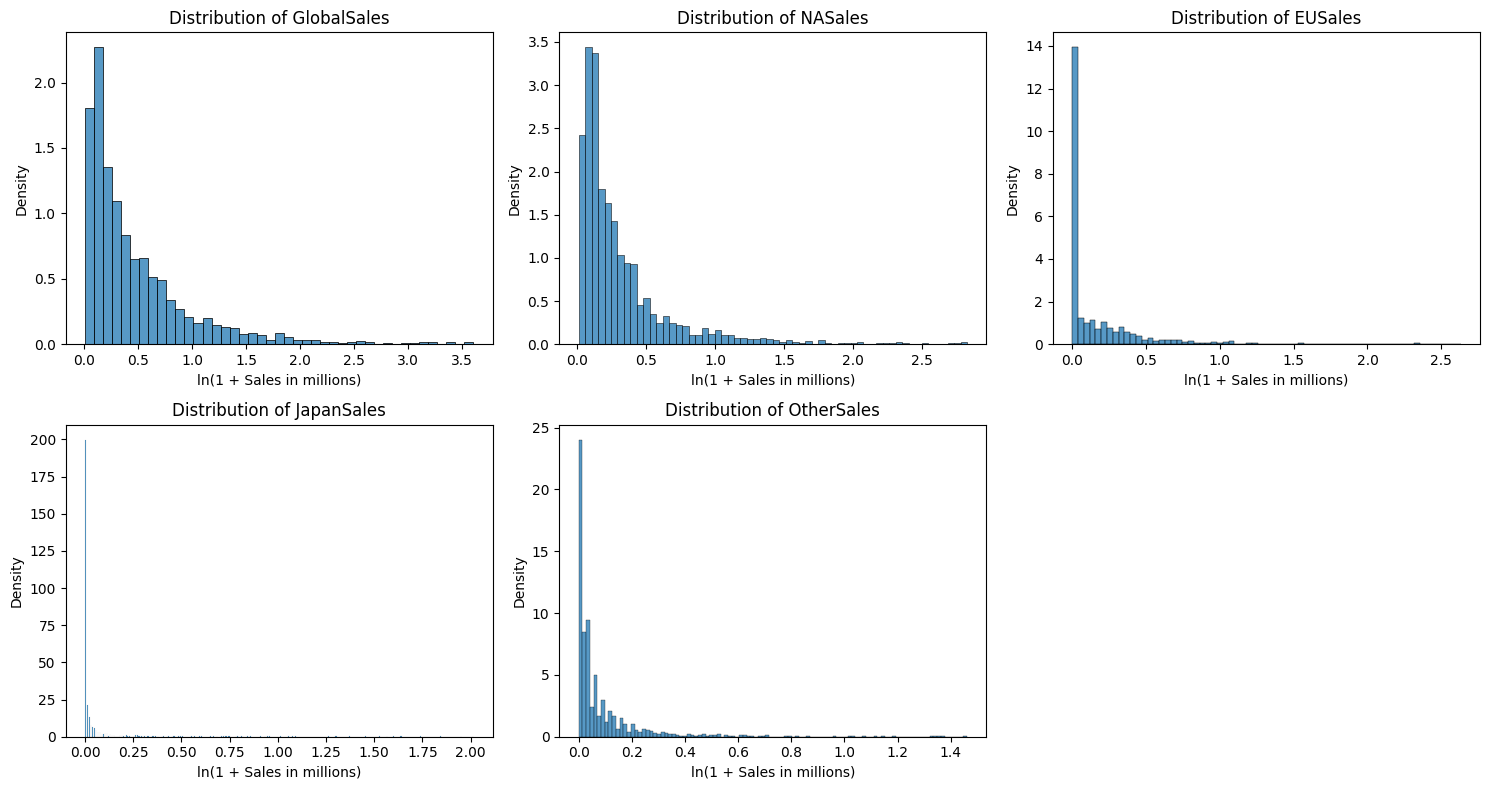

In [59]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))

axes = axes.flatten()

for ax, col in zip(axes, sales_cols):
    sns.histplot(
        x=np.log1p(numerical_df[col].dropna()),
        bins="auto",
        kde=False,
        stat="density",
        ax=ax,
    )
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("ln(1 + Sales in millions)")
    ax.set_ylabel("Density")

for ax in axes[len(sales_cols) :]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [60]:
sales_df = numerical_df[sales_cols]

Q1 = sales_df.quantile(0.25)
Q3 = sales_df.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = sales_df.lt(lower_bound) | sales_df.gt(upper_bound)

In [61]:
outlier_rows = df.loc[outliers.any(axis=1)].copy()
outlier_rows.shape

(437, 31)

In [62]:
for col in sales_cols:
    outlier_rows[f"{col}_Outlier"] = outliers.loc[outlier_rows.index, col]

outlier_rows["OutlierCount"] = outliers.loc[outlier_rows.index].sum(axis=1)

outlier_rows.to_csv("sales_outliers.csv", index=False)

In [63]:
labels = [
    "The worst of the worst",
    "Generally unfavourable",
    "Mixed/average",
    "Generally favourable",
    "Universally acclaimed",
]

bins = [0, 20, 50, 75, 90, 101]

df["ReviewCategory"] = pd.cut(
    df["ReviewScore"],
    bins=bins,
    labels=labels,
    right=False,
)

In [64]:
df.head()

,Console,Title,YearReleased,Genre,NASales,EUSales,JapanSales,OtherSales,GlobalSales,Sequel,...,Puzzle,RealTime,SciFi,Shooter,FirstPerson,Isometric,SideScrolling,TopDown,ThirdPerson,ReviewCategory
0,Sony PSP,007: From Russia with Love,2006,"Action, Racing / Driving",0.07,0.01,0.00,0.01,0.08,1,...,False,False,False,False,False,False,False,False,False,Mixed/average
1,Sony PSP,300: March to Glory,2007,Action,0.27,0.08,0.00,0.06,0.41,0,...,False,False,False,False,False,False,False,False,True,Mixed/average
2,PlayStation 3,3D Dot Game Heroes,2010,"Action, Adventure, Strategy",0.36,0.12,0.03,0.07,0.58,0,...,True,False,False,False,False,False,False,False,True,Generally favourable
3,X360,50 Cent: Blood on the Sand,2009,Action,0.12,0.07,0.00,0.02,0.21,1,...,False,False,False,True,False,False,False,False,True,Mixed/average
4,PlayStation 3,50 Cent: Blood on the Sand,2009,Action,0.10,0.06,0.01,0.03,0.20,1,...,False,False,False,True,False,False,False,False,True,Mixed/average


In [65]:
review_proportions = (
    df["ReviewCategory"].value_counts(normalize=True, sort=False).mul(100)
)

review_summary = pd.DataFrame(
    {
        "Frequency": df["ReviewCategory"].value_counts(sort=False),
        "Proportion (%)": (review_proportions.round(2)),
    }
)

display(review_summary)

,Frequency,Proportion (%)
The worst of the worst,4,0.23
Generally unfavourable,170,9.69
Mixed/average,941,53.65
Generally favourable,578,32.95
Universally acclaimed,61,3.48


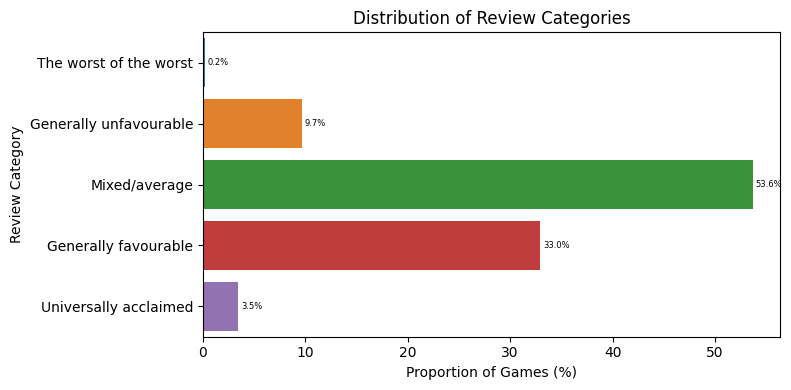

In [66]:
fig, ax = plt.subplots(figsize=(8, 4))

sns.barplot(
    x=review_proportions.values,
    y=review_proportions.index,
    orient="h",
    ax=ax,
)

ax.set_title("Distribution of Review Categories")
ax.set_xlabel("Proportion of Games (%)")
ax.set_ylabel("Review Category")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=2, fontsize=6)

plt.tight_layout()
plt.show()

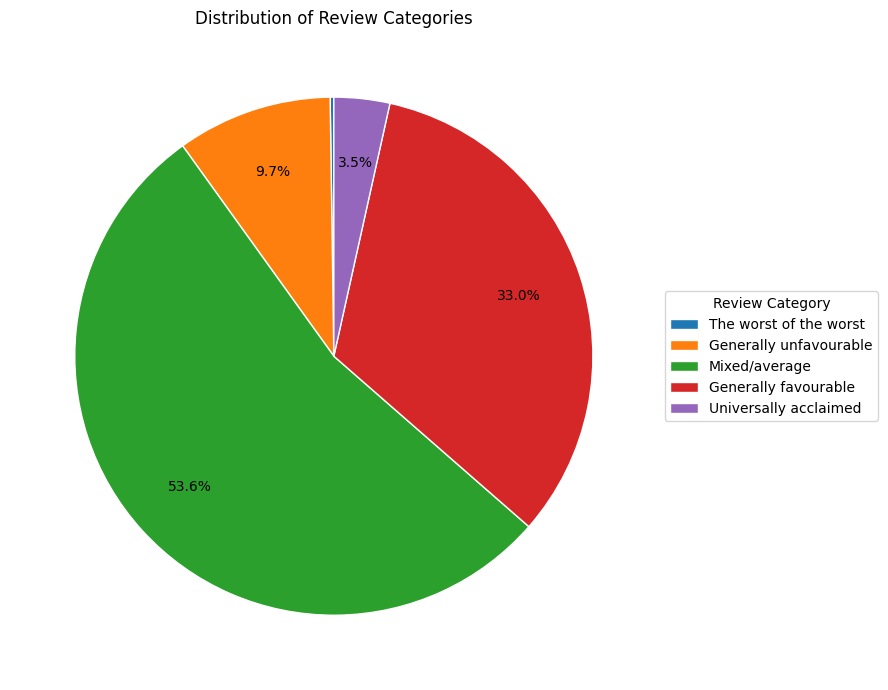

In [67]:
fig, ax = plt.subplots(figsize=(9, 7))

ax.pie(
    review_proportions.values,
    labels=None,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 3 else "",
    startangle=90,
    pctdistance=0.75,
    wedgeprops={"edgecolor": "white"},
)

ax.legend(
    review_proportions.index,
    title="Review Category",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
)

ax.set_title("Distribution of Review Categories")

plt.tight_layout()
plt.show()

In [68]:
regional_sales = df[["NASales", "EUSales", "JapanSales"]]

correlation_matrix = regional_sales.corr(method="pearson")

display(correlation_matrix.round(3))

,NASales,EUSales,JapanSales
NASales,1.000,0.894,0.646
EUSales,0.894,1.000,0.709
JapanSales,0.646,0.709,1.000


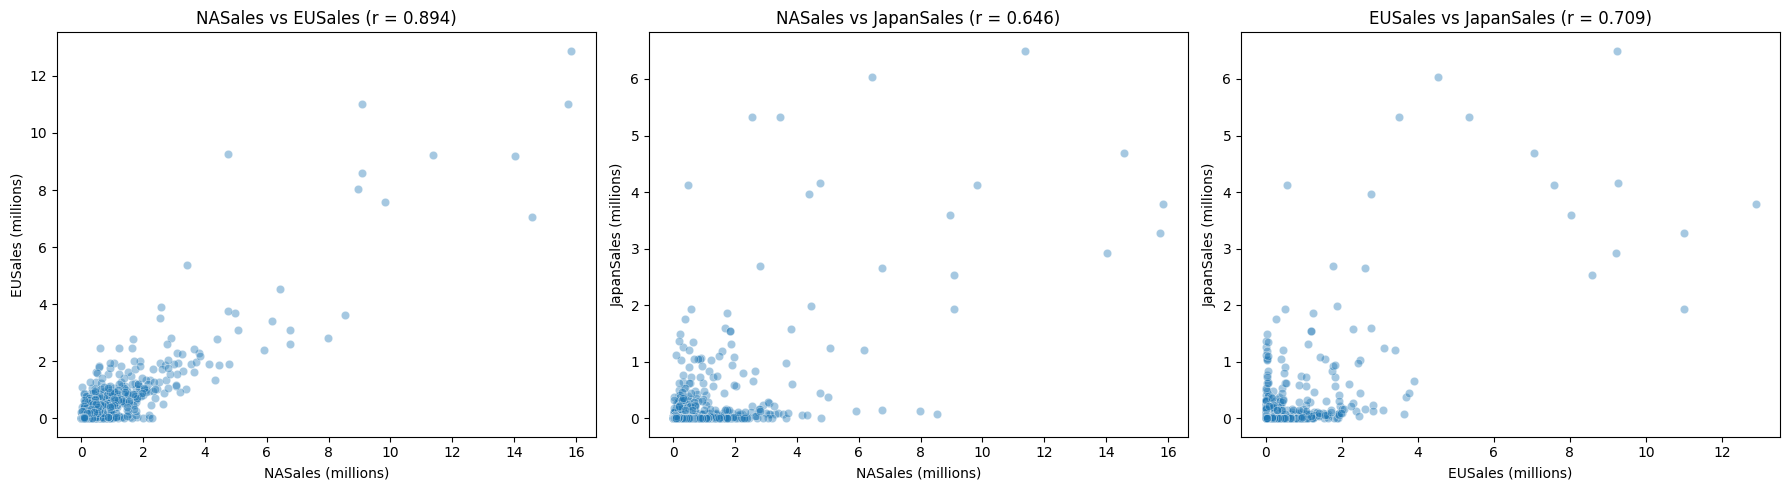

In [69]:
sales_pairs = [
    ("NASales", "EUSales"),
    ("NASales", "JapanSales"),
    ("EUSales", "JapanSales"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (x, y) in zip(axes, sales_pairs):
    r = df[[x, y]].corr().iloc[0, 1]

    sns.scatterplot(
        data=df,
        x=x,
        y=y,
        alpha=0.4,
        ax=ax,
    )

    ax.set_title(f"{x} vs {y} (r = {r:.3f})")
    ax.set_xlabel(f"{x} (millions)")
    ax.set_ylabel(f"{y} (millions)")

plt.tight_layout()
plt.show()

In [70]:
results = []

for x, y in sales_pairs:
    data = df[[x, y]].dropna()

    r = data[x].corr(data[y])

    slope = r * data[y].std() / data[x].std()

    intercept = data[y].mean() - slope * data[x].mean()

    results.append({
        "X": x,
        "Y": y,
        "Correlation (r)": r,
        "Slope (m)": slope,
        "Intercept (b)": intercept,
    })

regression_results = pd.DataFrame(results)

display(regression_results.round(3))

,X,Y,Correlation (r),Slope (m),Intercept (b)
0,NASales,EUSales,0.894,0.671,-0.050
1,NASales,JapanSales,0.646,0.254,-0.034
2,EUSales,JapanSales,0.709,0.371,-0.013


In [71]:
for _, row in regression_results.iterrows():
    print(
        f"{row['Y']} ="
        f"{row['Slope (m)']:.3f}({row['X']})"
        f"{row['Intercept (b)']:+.3f}"
    )

EUSales =0.671(NASales)-0.050
JapanSales =0.254(NASales)-0.034
JapanSales =0.371(EUSales)-0.013


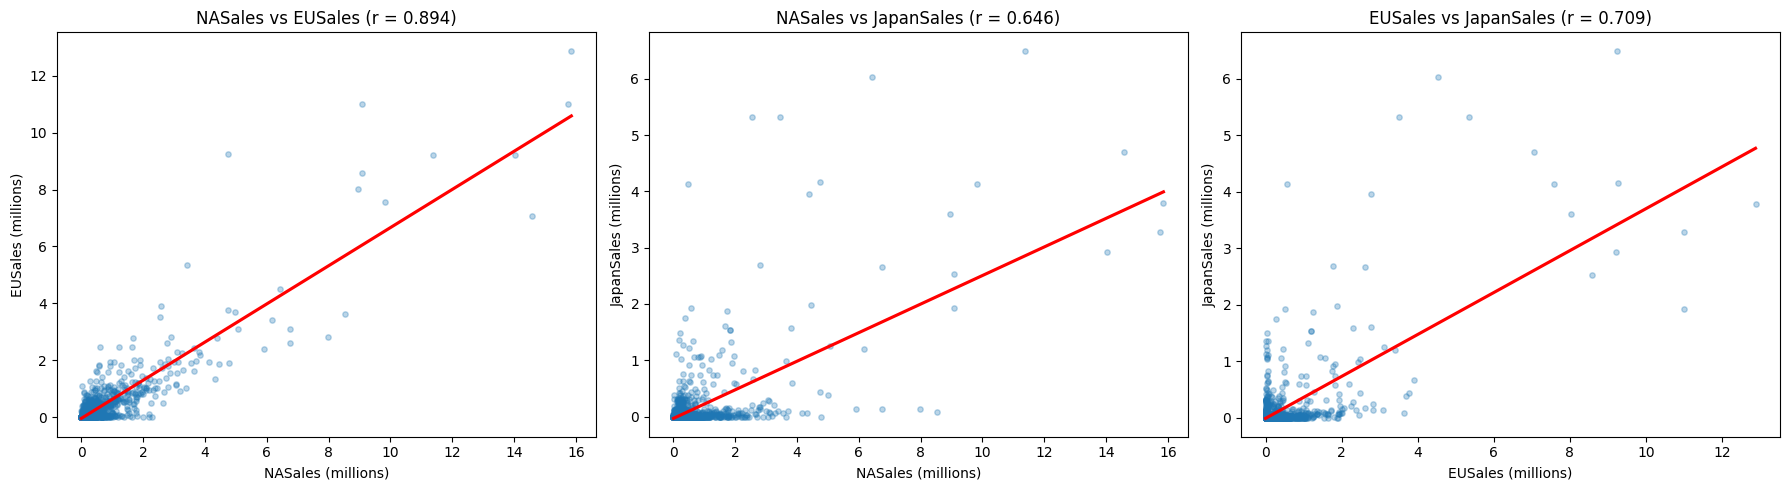

In [72]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (x, y) in zip(axes, sales_pairs):
    r = df[x].corr(df[y])

    sns.regplot(
        data=df,
        x=x,
        y=y,
        ax=ax,
        ci=None,
        scatter_kws={"alpha": 0.3, "s": 15},
        line_kws={"color": "red"},
    )

    ax.set_title(f"{x} vs {y} (r = {r:.3f})")
    ax.set_xlabel(f"{x} (millions)")
    ax.set_ylabel(f"{y} (millions)")

plt.tight_layout()
plt.show()

In [73]:
# Check for missing values in the "Genre" column
df["Genre"].isna().sum()

0

In [74]:
# Create a new column "ActionRelated" that indicates whether the game is related to the Action genre
df["ActionRelated"] = df["Genre"].str.contains(
    r"\bAction\b",
    case=False,
    na=False,
    regex=True,
)

In [75]:
# Determine the association between "ActionRelated" and "FirstPerson"
contingency_table = pd.crosstab(
    df["ActionRelated"],
    df["FirstPerson"],
    margins=True,
    margins_name="Total",
)

contingency_table.index.name = "Action-related"
contingency_table.columns.name = "First-person"

display(contingency_table)

First-person,False,True,Total
Action-related,,,
False,519,168,687
True,812,255,1067
Total,1331,423,1754


In [76]:
proportions = pd.crosstab(
    df["ActionRelated"],
    df["FirstPerson"],
    normalize="index",
) * 100

display(proportions.round(2))

FirstPerson,False,True
ActionRelated,,
False,75.55,24.45
True,76.10,23.90


In [77]:
# Odds of being first-person among Action-related games
odds_action = (contingency_table.loc[True, True] / contingency_table.loc[True, False])

# Odds of being first-person among non-Action-related games
odds_non_action = (
    contingency_table.loc[False, True] / contingency_table.loc[False, False]
)

# Odds Ratio
OR = odds_action / odds_non_action

print(f"Odds Ratio (OR): {OR:.3f}")

Odds Ratio (OR): 0.970


<p>
Both Risk Ratio (RR) and Odds Ratio (OR) can be used to examine the association between Action-related and first person gameplay. This is an observational study using existing data; its is not an experiment or cohort study that follows subjects over time. Since RR measures the relative risk of an event developing over time, the RR is more appropriately interpreted as a ratio of conditional proportions rather than the risk of a game developing first-person gameplay.

A suitable alternative for describing the association without interpreting the outcome as a risk developing over time is OR. The odds of a game being first-person are ~0.97 times as high for Action-related games compared to non-action related games. Since the OR is very close to 1, this indicates a very weak negative association in the sample. 

However, this odds ratio alone does not tell us whether this association is statistically significant; hypothesis test is required to determine whether there is evidence of an association at the population level. 
<p>

In [78]:
contingency_table = pd.crosstab(df["ActionRelated"], df["FirstPerson"])

# Chi-squared test
chi2, p_value, dof, expected = chi2_contingency(contingency_table, correction=False)

print(f"Chi-squared statistic: {chi2:.4f}")
print(f"p-value: {p_value:.4f}")

Chi-squared statistic: 0.0704
p-value: 0.7907
